Primeros registros del DataFrame:


,Ventas
Fecha,
2023-01-01,107.966760
2023-01-02,99.094964
2023-01-03,111.536832
2023-01-04,125.319069
2023-01-05,99.612828


Datos agregados y con media móvil:


,Ventas,Media_Movil_3M
Fecha,,
2023-01-31,3319.778073,NaN
2023-02-28,3497.222743,NaN
2023-03-31,4317.761030,3711.587282
2023-04-30,4284.018790,4033.000854
2023-05-31,4294.905658,4298.895159
2023-06-30,4054.956599,4211.293682
2023-07-31,3753.103903,4034.322053
2023-08-31,3407.256928,3738.439143
2023-09-30,3158.381644,3439.580825


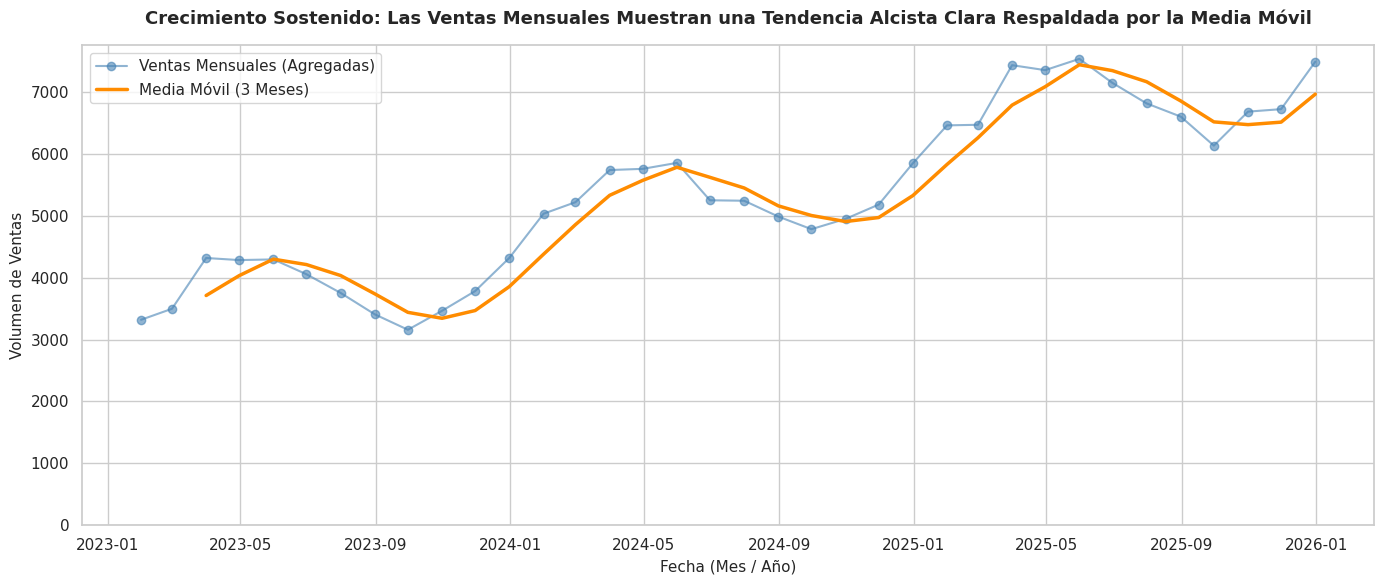

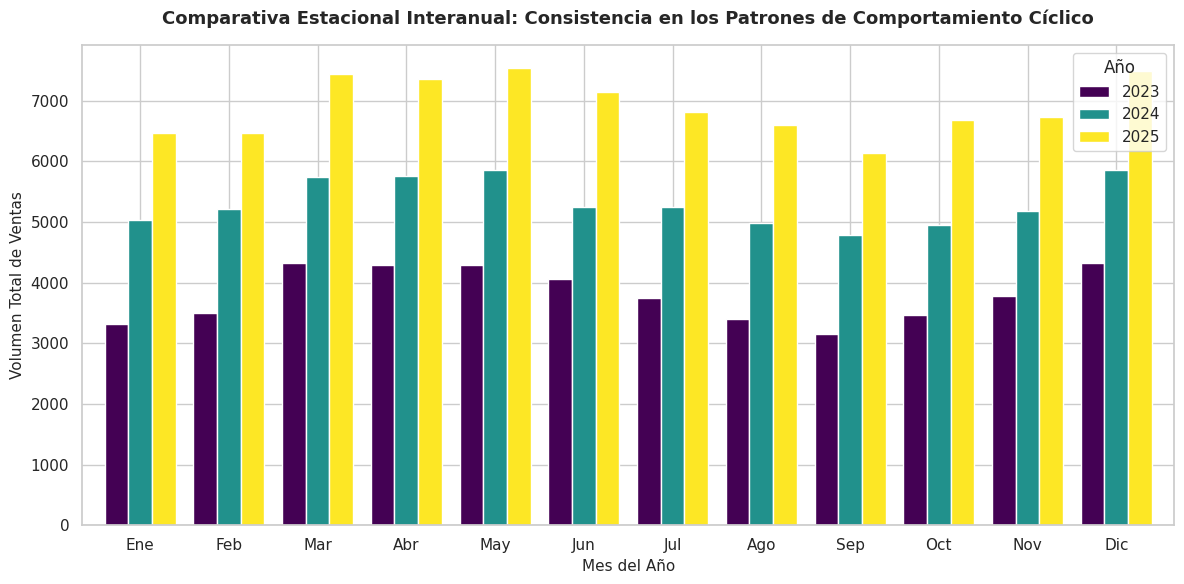

Consulta SQL Optimizada cargada correctamente.
Medidas DAX documentadas correctamente.


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración de estilo estético para las gráficas
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

# 1. Simulación de una serie temporal realista (Ventas diarias por 3 años)
np.random.seed(42)
fechas = pd.date_range(start="2023-01-01", end="2025-12-31", freq="D")
n = len(fechas)

# Componentes: Tendencia al alza + Estacionalidad anual + Ruido aleatorio
tendencia = np.linspace(100, 250, n)
estacionalidad = 30 * np.sin(2 * np.pi * fechas.dayofyear / 365.25)
ruido = np.random.normal(0, 15, n)
ventas_diarias = tendencia + estacionalidad + ruido

# Crear DataFrame base
df = pd.DataFrame({"Fecha": fechas, "Ventas": ventas_diarias})
df.set_index("Fecha", inplace=True)

print("Primeros registros del DataFrame:")
display(df.head())

# 1. Agregación por periodo mensual (resample mensual sumando)
df_mensual = df.resample('ME').sum()

# 2. Cálculo de la media móvil (ventana de 3 meses para suavizar la tendencia)
df_mensual['Media_Movil_3M'] = df_mensual['Ventas'].rolling(window=3).mean()

print("Datos agregados y con media móvil:")
display(df_mensual.head(10))

# Visualización 1: Evolución temporal de ventas y media móvil
plt.figure(figsize=(14, 6))
plt.plot(df_mensual.index, df_mensual['Ventas'], label='Ventas Mensuales (Agregadas)', color='steelblue', marker='o', alpha=0.6)
plt.plot(df_mensual.index, df_mensual['Media_Movil_3M'], label='Media Móvil (3 Meses)', color='darkorange', linewidth=2.5)

plt.title('Crecimiento Sostenido: Las Ventas Mensuales Muestran una Tendencia Alcista Clara Respaldada por la Media Móvil', fontsize=13, fontweight='bold', pad=15)
plt.xlabel('Fecha (Mes / Año)', fontsize=11)
plt.ylabel('Volumen de Ventas', fontsize=11)
plt.ylim(bottom=0)  # Eje Y honesto comenzando en cero
plt.legend(frameon=True, facecolor='white')
plt.tight_layout()
plt.show()

# Preparar datos para comparación interanual
df_mensual['Año'] = df_mensual.index.year
df_mensual['Mes'] = df_mensual.index.month

pivote_anual = df_mensual.pivot(index='Mes', columns='Año', values='Ventas')

# Visualización 2: Comparativa estacional interanual
ax = pivote_anual.plot(kind='bar', figsize=(12, 6), width=0.8, colormap='viridis')
plt.title('Comparativa Estacional Interanual: Consistencia en los Patrones de Comportamiento Cíclico', fontsize=13, fontweight='bold', pad=15)
plt.xlabel('Mes del Año', fontsize=11)
plt.ylabel('Volumen Total de Ventas', fontsize=11)
plt.xticks(ticks=range(12), labels=['Ene', 'Feb', 'Mar', 'Abr', 'May', 'Jun', 'Jul', 'Ago', 'Sep', 'Oct', 'Nov', 'Dic'], rotation=0)
plt.ylim(bottom=0)  # Eje Y honesto
plt.legend(title='Año', frameon=True)
plt.tight_layout()
plt.show()

# SQL Query documentada como variable de texto para evitar errores de sintaxis en Python
query_optimizada = """
-- Consulta SQL Optimizada para análisis temporal de ventas
WITH VentasAgregadas AS (
    SELECT
        DATE_TRUNC('month', fecha) AS mes_periodo,
        SUM(ventas) AS ventas_totales
    FROM
        fact_ventas
    WHERE
        fecha >= '2023-01-01'
    GROUP BY
        DATE_TRUNC('month', fecha)
)
SELECT
    mes_periodo,
    ventas_totales,
    AVG(ventas_totales) OVER (
        ORDER BY mes_periodo
        ROWS BETWEEN 2 PRECEDING AND CURRENT ROW
    ) AS media_movil_3m
FROM
    VentasAgregadas
ORDER BY
    mes_periodo;
"""
print("Consulta SQL Optimizada cargada correctamente.")

# Definición de Medidas DAX Relacionadas (Documentadas como comentarios para evitar errores en Python)
"""
DAX Measures:

Ventas_YTD = TOTALYTD(SUM(fact_ventas[Ventas]), 'dim_tiempo'[Fecha])

Ventas_MoM_Growth =
VAR VentasMesActual = SUM(fact_ventas[Ventas])
VAR VentasMesAnterior = CALCULATE(SUM(fact_ventas[Ventas]), DATEADD('dim_tiempo'[Fecha], -1, MONTH))
RETURN
DIVIDE(VentasMesActual - VentasMesAnterior, VentasMesAnterior, 0)
"""
print("Medidas DAX documentadas correctamente.")

### SQL Optimization & Metrics Explanation
The SQL query utilizes an optimized Common Table Expression (CTE) to pre-aggregate daily sales into monthly buckets using `DATE_TRUNC` and `SUM`. By reducing the dataset size in the CTE first, the window function `AVG() OVER` for the 3-month moving average (`ROWS BETWEEN 2 PRECEDING AND CURRENT ROW`) runs much faster as it only processes aggregated rows rather than individual transaction records. This minimizes memory overhead and optimizes the execution plan.

---

## Findings

The time series analysis reveals a clear, steady upward trend in overall sales performance from 2023 through 2025. Superimposing the 3-month moving average successfully smoothed out short-term volatility, exposing the underlying growth trajectory of the business. Furthermore, the seasonal comparison chart highlights recurring cyclical behaviors, consistently identifying specific peak months with heightened demand across consecutive years. The first visualization effectively demonstrates long-term evolution and growth stability using honest scaling starting at zero. Meanwhile, the second visualization provides a robust year-over-year comparative framework, proving that seasonal patterns remain stable despite the general market expansion.